In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.simplefilter('ignore')

In [2]:
df = pd.read_csv("agentic_reality.csv")
df.head()

,Project_ID,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score
0,AGP-0001,Insurance,Autonomous,LangGraph,Production,NaN,0.389,2094,2.51
1,AGP-0002,Retail,Assistant,CrewAI,Production,NaN,0.990,5993,3.78
2,AGP-0003,Energy,Multi-agent Swarm,AutoGPT 3.0,Pilot,Loop Error,0.475,9032,0.91
3,AGP-0004,Technology,Multi-agent Swarm,LangGraph,Pilot,Loop Error,0.372,8735,0.75
4,AGP-0005,Finance,Autonomous,LangGraph,Production,NaN,0.613,1645,2.58


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Project_ID               2500 non-null   object 
 1   Industry                 2500 non-null   object 
 2   Agent_Type               2500 non-null   object 
 3   Primary_Tool             2500 non-null   object 
 4   Status                   2500 non-null   object 
 5   Failure_Reason           2154 non-null   object 
 6   Human_in_the_Loop_Ratio  2500 non-null   float64
 7   Tokens_per_Task          2500 non-null   int64  
 8   ROI_Score                2500 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 175.9+ KB


In [4]:
df.isnull().sum()

Project_ID                   0
Industry                     0
Agent_Type                   0
Primary_Tool                 0
Status                       0
Failure_Reason             346
Human_in_the_Loop_Ratio      0
Tokens_per_Task              0
ROI_Score                    0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.drop('Project_ID', axis=1)

,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score
0,Insurance,Autonomous,LangGraph,Production,NaN,0.389,2094,2.51
1,Retail,Assistant,CrewAI,Production,NaN,0.990,5993,3.78
2,Energy,Multi-agent Swarm,AutoGPT 3.0,Pilot,Loop Error,0.475,9032,0.91
3,Technology,Multi-agent Swarm,LangGraph,Pilot,Loop Error,0.372,8735,0.75
4,Finance,Autonomous,LangGraph,Production,NaN,0.613,1645,2.58
...,...,...,...,...,...,...,...,...
2495,Manufacturing,Autonomous,CrewAI,Pilot,Loop Error,0.266,5788,-0.14
2496,Manufacturing,Autonomous,LangGraph,Pilot,Schema Drift,0.162,3609,1.73
2497,Healthcare,Assistant,CrewAI,Pilot,Security Violation,0.799,3182,0.63
2498,Energy,Assistant,CrewAI,Pilot,Loop Error,0.571,5360,-0.28


In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['Agent_Type_enc'] = le.fit_transform(df['Agent_Type'])
df[['Agent_Type', 'Agent_Type_enc']].drop_duplicates()

,Agent_Type,Agent_Type_enc
0,Autonomous,1
1,Assistant,0
2,Multi-agent Swarm,2


In [10]:
X = df[['Agent_Type_enc','Human_in_the_Loop_Ratio', 'Tokens_per_Task', 'ROI_Score']].values
X[:5]

array([[1.000e+00, 3.890e-01, 2.094e+03, 2.510e+00],
       [0.000e+00, 9.900e-01, 5.993e+03, 3.780e+00],
       [2.000e+00, 4.750e-01, 9.032e+03, 9.100e-01],
       [2.000e+00, 3.720e-01, 8.735e+03, 7.500e-01],
       [1.000e+00, 6.130e-01, 1.645e+03, 2.580e+00]])

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [12]:
from sklearn.cluster import KMeans

In [13]:
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
print(wcss)

[10000.0, 6602.167363646357, 5195.145126059729, 4229.895771612875, 3769.448602302932, 3288.192620321149, 3053.5783583199677, 2887.469120334808, 2624.970123582683, 2472.3517549953003]


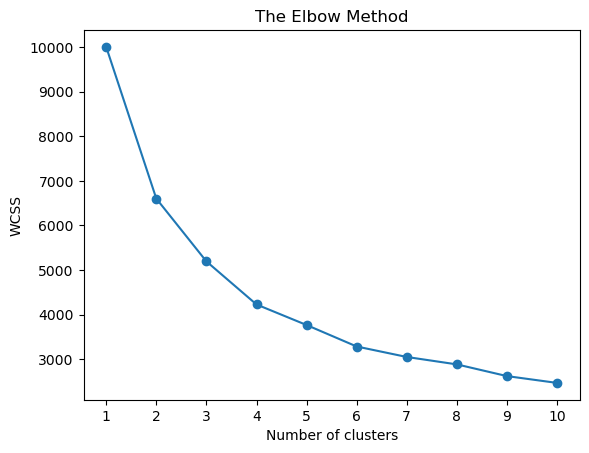

In [14]:
plt.plot(range(1, 11), wcss, marker='o')
plt.xticks(range(1, 11))
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

## K-Means Model

In [15]:
kmeans = KMeans(n_clusters=4, init='k-means++', random_state=42)

In [16]:
y_kmeans = kmeans.fit_predict(X_scaled)

In [17]:
y_kmeans

array([0, 0, 2, ..., 3, 3, 3], shape=(2500,), dtype=int32)

In [18]:
df['cluster'] = y_kmeans
df.head()

,Project_ID,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score,Agent_Type_enc,cluster
0,AGP-0001,Insurance,Autonomous,LangGraph,Production,NaN,0.389,2094,2.51,1,0
1,AGP-0002,Retail,Assistant,CrewAI,Production,NaN,0.990,5993,3.78,0,0
2,AGP-0003,Energy,Multi-agent Swarm,AutoGPT 3.0,Pilot,Loop Error,0.475,9032,0.91,2,2
3,AGP-0004,Technology,Multi-agent Swarm,LangGraph,Pilot,Loop Error,0.372,8735,0.75,2,2
4,AGP-0005,Finance,Autonomous,LangGraph,Production,NaN,0.613,1645,2.58,1,0


## Inspecting the clusters

In [19]:
df.groupby('cluster')[['Human_in_the_Loop_Ratio', 'Tokens_per_Task', 'ROI_Score']].mean()

,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score
cluster,,,
0,0.657805,4358.289694,2.727716
1,0.218465,4177.438017,0.098666
2,0.464625,7934.750449,-0.079174
3,0.722312,4542.693351,0.061872


In [20]:
df.groupby('cluster')['Agent_Type'].value_counts(normalize=True).unstack().round(2)

Agent_Type,Assistant,Autonomous,Multi-agent Swarm
cluster,,,
0,0.70,0.24,0.07
1,0.02,0.87,0.11
2,0.01,0.14,0.85
3,0.97,0.03,NaN


In [21]:
df.groupby('cluster')['Status'].value_counts(normalize=True).unstack().round(2)

Status,Abandoned,Pilot,Production
cluster,,,
0,NaN,0.21,0.79
1,0.46,0.51,0.03
2,0.41,0.55,0.04
3,0.37,0.61,0.02


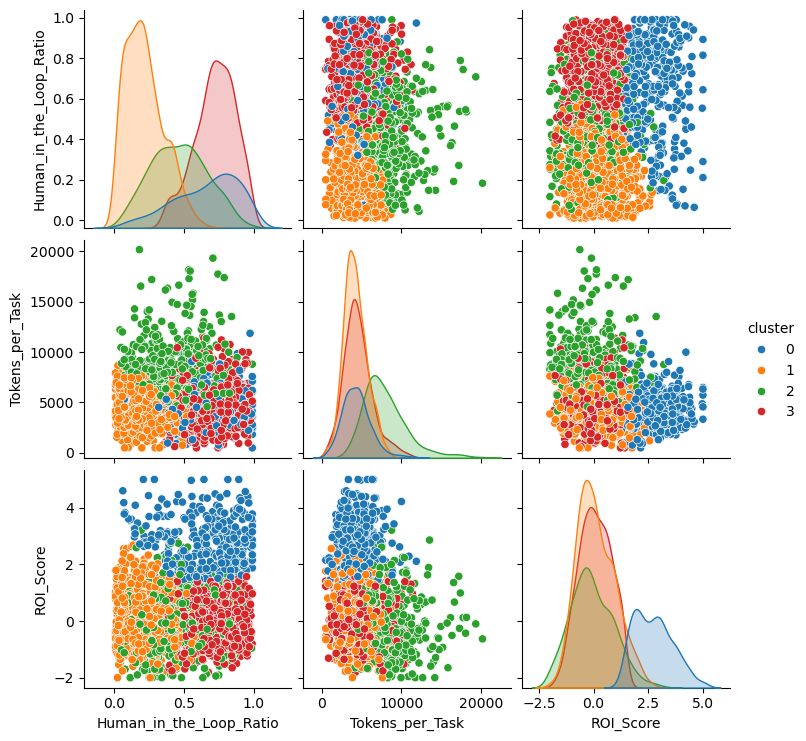

In [22]:
sns.pairplot(df, vars=['Human_in_the_Loop_Ratio', 'Tokens_per_Task', 'ROI_Score'], hue='cluster', palette='tab10')
plt.show()

In [23]:
df[df['cluster'] == 0]

,Project_ID,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score,Agent_Type_enc,cluster
0,AGP-0001,Insurance,Autonomous,LangGraph,Production,NaN,0.389,2094,2.51,1,0
1,AGP-0002,Retail,Assistant,CrewAI,Production,NaN,0.990,5993,3.78,0,0
4,AGP-0005,Finance,Autonomous,LangGraph,Production,NaN,0.613,1645,2.58,1,0
9,AGP-0010,Retail,Assistant,LangGraph,Production,NaN,0.724,4428,4.49,0,0
10,AGP-0011,Retail,Assistant,LangGraph,Production,NaN,0.780,3022,3.33,0,0
...,...,...,...,...,...,...,...,...,...,...,...
2449,AGP-2450,Technology,Assistant,CrewAI,Production,NaN,0.909,2793,4.26,0,0
2455,AGP-2456,Manufacturing,Autonomous,CrewAI,Pilot,Loop Error,0.591,4524,1.57,1,0
2457,AGP-2458,Finance,Autonomous,AutoGPT 3.0,Pilot,Loop Error,0.374,5322,1.93,1,0
2469,AGP-2470,Legal,Assistant,CrewAI,Production,NaN,0.734,2688,2.82,0,0


In [24]:
df[df['cluster'] == 1]

,Project_ID,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score,Agent_Type_enc,cluster
5,AGP-0006,Telecom,Autonomous,CrewAI,Abandoned,Schema Drift,0.168,3713,-0.38,1,1
12,AGP-0013,Technology,Autonomous,LangGraph,Pilot,Schema Drift,0.128,2146,1.51,1,1
13,AGP-0014,Energy,Autonomous,CrewAI,Abandoned,Cost Overrun,0.132,5087,-0.49,1,1
14,AGP-0015,Retail,Autonomous,LangGraph,Abandoned,Security Violation,0.199,5113,-0.47,1,1
15,AGP-0016,Healthcare,Multi-agent Swarm,LangGraph,Pilot,Cost Overrun,0.223,2330,1.66,2,1
...,...,...,...,...,...,...,...,...,...,...,...
2483,AGP-2484,Legal,Autonomous,AutoGPT 3.0,Abandoned,Loop Error,0.204,6191,-1.08,1,1
2487,AGP-2488,Energy,Autonomous,LangGraph,Abandoned,Loop Error,0.434,3615,-0.66,1,1
2489,AGP-2490,Technology,Autonomous,LangGraph,Pilot,Schema Drift,0.338,3311,0.35,1,1
2495,AGP-2496,Manufacturing,Autonomous,CrewAI,Pilot,Loop Error,0.266,5788,-0.14,1,1


In [25]:
df[df['cluster'] == 2]

,Project_ID,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score,Agent_Type_enc,cluster
2,AGP-0003,Energy,Multi-agent Swarm,AutoGPT 3.0,Pilot,Loop Error,0.475,9032,0.91,2,2
3,AGP-0004,Technology,Multi-agent Swarm,LangGraph,Pilot,Loop Error,0.372,8735,0.75,2,2
6,AGP-0007,Insurance,Multi-agent Swarm,AutoGPT 3.0,Abandoned,Schema Drift,0.478,10530,-1.51,2,2
7,AGP-0008,Insurance,Multi-agent Swarm,CrewAI,Abandoned,Cost Overrun,0.224,6478,-0.71,2,2
26,AGP-0027,Retail,Multi-agent Swarm,CrewAI,Abandoned,Loop Error,0.517,7098,-0.77,2,2
...,...,...,...,...,...,...,...,...,...,...,...
2480,AGP-2481,Manufacturing,Multi-agent Swarm,CrewAI,Pilot,Security Violation,0.607,9637,-0.89,2,2
2485,AGP-2486,Retail,Autonomous,AutoGPT 3.0,Abandoned,Loop Error,0.271,8231,-0.69,1,2
2488,AGP-2489,Finance,Multi-agent Swarm,LangGraph,Pilot,Security Violation,0.667,4579,-0.29,2,2
2490,AGP-2491,Telecom,Autonomous,AutoGPT 3.0,Pilot,Loop Error,0.335,9067,1.36,1,2


In [26]:
df[df['cluster'] == 3]

,Project_ID,Industry,Agent_Type,Primary_Tool,Status,Failure_Reason,Human_in_the_Loop_Ratio,Tokens_per_Task,ROI_Score,Agent_Type_enc,cluster
8,AGP-0009,Finance,Assistant,CrewAI,Production,NaN,0.795,2821,1.22,0,3
18,AGP-0019,Energy,Assistant,CrewAI,Pilot,Cost Overrun,0.717,2893,-0.38,0,3
21,AGP-0022,Legal,Assistant,AutoGPT 3.0,Pilot,Security Violation,0.660,6223,0.86,0,3
22,AGP-0023,Telecom,Assistant,AutoGPT 3.0,Pilot,Schema Drift,0.748,6457,1.12,0,3
23,AGP-0024,Government,Assistant,CrewAI,Pilot,Loop Error,0.708,8152,-0.89,0,3
...,...,...,...,...,...,...,...,...,...,...,...
2493,AGP-2494,Government,Assistant,LangGraph,Pilot,Security Violation,0.918,4339,-0.13,0,3
2494,AGP-2495,Government,Assistant,AutoGPT 3.0,Pilot,Cost Overrun,0.815,6735,1.23,0,3
2497,AGP-2498,Healthcare,Assistant,CrewAI,Pilot,Security Violation,0.799,3182,0.63,0,3
2498,AGP-2499,Energy,Assistant,CrewAI,Pilot,Loop Error,0.571,5360,-0.28,0,3
